HIGH PERFORMANCE COMPUTING - ANALISIS PM2.5
GPU tersedia : Tesla T4
PyTorch      : 2.11.0+cu130
CPU threads  : 2

Mengunduh dataset dari UCI...
Jumlah file CSV valid: 12
Jumlah baris awal: 420768

HASIL PREPROCESSING
Baris awal    : 420768
Baris valid   : 412029
Baris dibuang : 8739
Jumlah stasiun: 12

Melakukan warm-up CPU dan GPU...
Validasi CPU dan GPU: BERHASIL

Menjalankan benchmark...
Uji 1: CPU=0.003278s | GPU=0.002374s | GPU total=0.003552s
Uji 2: CPU=0.003169s | GPU=0.002305s | GPU total=0.003515s
Uji 3: CPU=0.003086s | GPU=0.002321s | GPU total=0.003503s
Uji 4: CPU=0.003692s | GPU=0.002343s | GPU total=0.004168s
Uji 5: CPU=0.003615s | GPU=0.002316s | GPU total=0.003527s
Uji 6: CPU=0.003145s | GPU=0.002305s | GPU total=0.003635s
Uji 7: CPU=0.003191s | GPU=0.002318s | GPU total=0.003535s

HASIL BENCHMARK HPC
CPU median         : 0.003191 detik
GPU median         : 0.002318 detik
GPU end-to-end     : 0.003535 detik
Speedup komputasi  : 1.38x
Speedup end-to-end : 0.90x
CPU lebih 

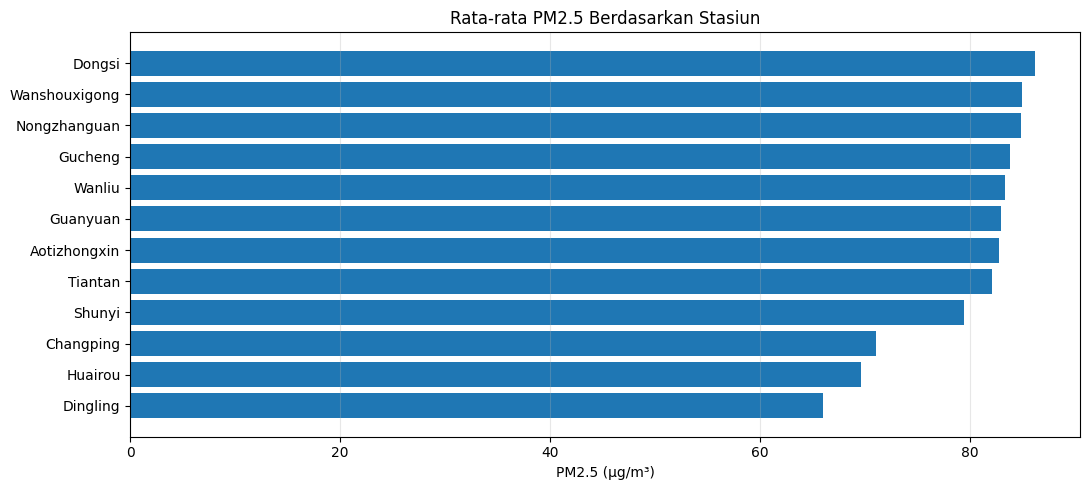

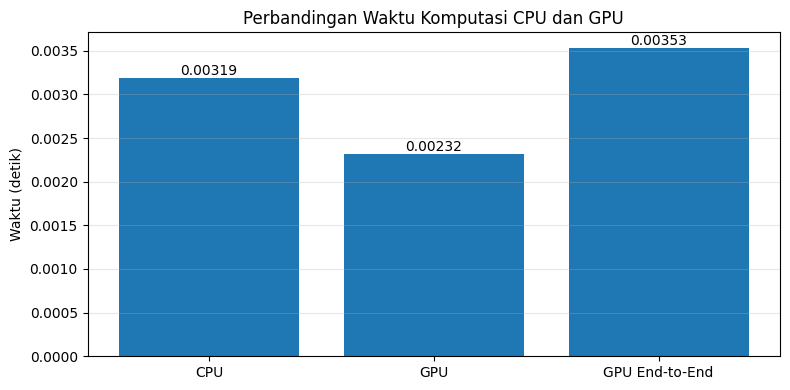


FILE HASIL
- hasil_hpc_pm25/benchmark_hpc.csv
- hasil_hpc_pm25/grafik_benchmark.png
- hasil_hpc_pm25/grafik_stasiun.png
- hasil_hpc_pm25/pm25_bulanan.csv
- hasil_hpc_pm25/ringkasan_hpc.csv
- hasil_hpc_pm25/statistik_stasiun.csv

Implementasi GPU-Accelerated HPC selesai.


In [1]:
import io
import os
import time
import zipfile
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ============================================================
# 1. KONFIGURASI
# ============================================================

DATASET_URL = (
    "https://archive.ics.uci.edu/static/public/501/"
    "beijing+multi+site+air+quality+data.zip"
)

OUTPUT_DIR = "hasil_hpc_pm25"
REPEATS = 7
WARMUP = 3

os.makedirs(OUTPUT_DIR, exist_ok=True)

torch.set_num_threads(min(2, os.cpu_count() or 1))

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU CUDA tidak tersedia. Aktifkan T4 GPU di Google Colab."
    )

gpu = torch.device("cuda:0")
cpu = torch.device("cpu")

print("=" * 60)
print("HIGH PERFORMANCE COMPUTING - ANALISIS PM2.5")
print("=" * 60)
print("GPU tersedia :", torch.cuda.get_device_name(0))
print("PyTorch      :", torch.__version__)
print("CPU threads  :", torch.get_num_threads())

# ============================================================
# 2. DOWNLOAD DAN EKSTRAK DATASET
# ============================================================

def extract_csv_files(blob):
    """Membaca semua CSV dari ZIP, termasuk ZIP bertingkat."""
    csv_files = []

    with zipfile.ZipFile(io.BytesIO(blob)) as archive:
        for name in archive.namelist():
            if name.lower().endswith(".csv"):
                csv_files.append(
                    (name, archive.read(name))
                )

            elif name.lower().endswith(".zip"):
                csv_files.extend(
                    extract_csv_files(archive.read(name))
                )

    return csv_files


print("\nMengunduh dataset dari UCI...")

request = Request(
    DATASET_URL,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urlopen(request, timeout=120) as response:
    blob = response.read()

csv_files = extract_csv_files(blob)

if not csv_files:
    raise RuntimeError("Tidak ada file CSV dalam dataset.")

frames = []

required = {
    "station", "year", "month", "day", "hour", "PM2.5"
}

for filename, content in csv_files:
    frame = pd.read_csv(io.BytesIO(content))

    if required.issubset(frame.columns):
        frames.append(frame)

if not frames:
    raise RuntimeError("Tidak ditemukan CSV dengan kolom PM2.5.")

data = pd.concat(frames, ignore_index=True)

print("Jumlah file CSV valid:", len(frames))
print("Jumlah baris awal:", len(data))

# ============================================================
# 3. PREPROCESSING
# ============================================================

for col in ["year", "month", "day", "hour", "PM2.5"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data["datetime"] = pd.to_datetime(
    data[["year", "month", "day", "hour"]],
    errors="coerce"
)

valid = (
    data["datetime"].notna()
    & data["PM2.5"].notna()
    & np.isfinite(data["PM2.5"])
    & (data["PM2.5"] >= 0)
    & data["station"].notna()
)

initial_rows = len(data)

data = data.loc[valid].copy()
data = data.sort_values(
    ["station", "datetime"]
).reset_index(drop=True)

if data.empty:
    raise RuntimeError("Dataset kosong setelah preprocessing.")

duplicates = data.duplicated(
    subset=["station", "datetime"]
).sum()

if duplicates:
    raise ValueError(
        f"Ditemukan {duplicates} timestamp duplikat."
    )

print("\nHASIL PREPROCESSING")
print("Baris awal    :", initial_rows)
print("Baris valid   :", len(data))
print("Baris dibuang :", initial_rows - len(data))
print("Jumlah stasiun:", data["station"].nunique())

# ============================================================
# 4. PERSIAPAN DATA TENSOR
# ============================================================

# Setiap baris merupakan pengamatan PM2.5 asli.
# Station ID digunakan untuk agregasi paralel.

station_codes, station_names = pd.factorize(
    data["station"], sort=True
)

values = data["PM2.5"].to_numpy(dtype=np.float32)

station_ids = torch.tensor(
    station_codes,
    dtype=torch.long
)

pm25_values = torch.tensor(
    values,
    dtype=torch.float32
)

num_stations = len(station_names)

# ============================================================
# 5. FUNGSI ANALISIS PARALEL
# ============================================================

def analyze_pm25(values_tensor, ids_tensor, n_stations):
    """
    Menghitung statistik PM2.5 setiap stasiun.

    scatter_add_ digunakan untuk menjumlahkan data
    berdasarkan indeks stasiun.
    """

    sums = torch.zeros(
        n_stations,
        device=values_tensor.device,
        dtype=torch.float64
    )

    counts = torch.zeros(
        n_stations,
        device=values_tensor.device,
        dtype=torch.float64
    )

    sums.scatter_add_(
        0,
        ids_tensor,
        values_tensor.to(torch.float64)
    )

    counts.scatter_add_(
        0,
        ids_tensor,
        torch.ones_like(
            values_tensor,
            dtype=torch.float64
        )
    )

    means = sums / counts.clamp(min=1)

    return means, counts


# ============================================================
# 6. PERSIAPAN CPU DAN GPU
# ============================================================

cpu_values = pm25_values.to(cpu)
cpu_ids = station_ids.to(cpu)

gpu_values = pm25_values.to(gpu)
gpu_ids = station_ids.to(gpu)

# ============================================================
# 7. WARM-UP
# ============================================================

print("\nMelakukan warm-up CPU dan GPU...")

with torch.inference_mode():
    for _ in range(WARMUP):
        cpu_result = analyze_pm25(
            cpu_values, cpu_ids, num_stations
        )

        gpu_result = analyze_pm25(
            gpu_values, gpu_ids, num_stations
        )

    torch.cuda.synchronize()

# ============================================================
# 8. VALIDASI CPU VS GPU
# ============================================================

cpu_means, cpu_counts = cpu_result
gpu_means, gpu_counts = gpu_result

gpu_means_cpu = gpu_means.cpu()
gpu_counts_cpu = gpu_counts.cpu()

if not torch.allclose(
    cpu_means,
    gpu_means_cpu,
    rtol=1e-6,
    atol=1e-5
):
    raise AssertionError(
        "Rata-rata CPU dan GPU tidak konsisten."
    )

if not torch.equal(cpu_counts, gpu_counts_cpu):
    raise AssertionError(
        "Jumlah data CPU dan GPU tidak konsisten."
    )

print("Validasi CPU dan GPU: BERHASIL")

# ============================================================
# 9. BENCHMARK KOMPUTASI CPU
# ============================================================

def benchmark_cpu():
    start = time.perf_counter()

    with torch.inference_mode():
        result = analyze_pm25(
            cpu_values,
            cpu_ids,
            num_stations
        )

    elapsed = time.perf_counter() - start
    return elapsed, result


# ============================================================
# 10. BENCHMARK KOMPUTASI GPU
# ============================================================

def benchmark_gpu():
    torch.cuda.synchronize()

    start_event = torch.cuda.Event(enable_timing=True)
    end_event = torch.cuda.Event(enable_timing=True)

    start_event.record()

    with torch.inference_mode():
        result = analyze_pm25(
            gpu_values,
            gpu_ids,
            num_stations
        )

    end_event.record()
    end_event.synchronize()

    elapsed = start_event.elapsed_time(end_event) / 1000

    return elapsed, result


# ============================================================
# 11. BENCHMARK END-TO-END GPU
# ============================================================

def benchmark_gpu_end_to_end():
    torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        x = cpu_values.to(gpu)
        ids = cpu_ids.to(gpu)

        result = analyze_pm25(
            x, ids, num_stations
        )

        result_cpu = (
            result[0].cpu(),
            result[1].cpu()
        )

    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    return elapsed, result_cpu


# ============================================================
# 12. PENGUJIAN KINERJA
# ============================================================

records = []

print("\nMenjalankan benchmark...")

for repeat in range(1, REPEATS + 1):

    methods = [
        ("CPU", benchmark_cpu),
        ("GPU", benchmark_gpu),
        ("GPU_End_to_End", benchmark_gpu_end_to_end)
    ]

    # Pergantian urutan pengujian
    if repeat % 2 == 0:
        methods.reverse()

    result_times = {}

    for name, function in methods:
        elapsed, _ = function()
        result_times[name] = elapsed

    records.append({
        "pengulangan": repeat,
        "cpu_detik": result_times["CPU"],
        "gpu_detik": result_times["GPU"],
        "gpu_end_to_end_detik": result_times["GPU_End_to_End"]
    })

    print(
        f"Uji {repeat}: "
        f"CPU={result_times['CPU']:.6f}s | "
        f"GPU={result_times['GPU']:.6f}s | "
        f"GPU total={result_times['GPU_End_to_End']:.6f}s"
    )

benchmark = pd.DataFrame(records)

cpu_median = float(benchmark["cpu_detik"].median())
gpu_median = float(benchmark["gpu_detik"].median())

gpu_total_median = float(
    benchmark["gpu_end_to_end_detik"].median()
)

speedup_compute = cpu_median / gpu_median
speedup_total = cpu_median / gpu_total_median

# ============================================================
# 13. HASIL BENCHMARK
# ============================================================

print("\n" + "=" * 60)
print("HASIL BENCHMARK HPC")
print("=" * 60)

print(f"CPU median         : {cpu_median:.6f} detik")
print(f"GPU median         : {gpu_median:.6f} detik")
print(f"GPU end-to-end     : {gpu_total_median:.6f} detik")
print(f"Speedup komputasi  : {speedup_compute:.2f}x")
print(f"Speedup end-to-end : {speedup_total:.2f}x")

if speedup_total > 1:
    print("GPU lebih cepat secara end-to-end.")
else:
    print(
        "CPU lebih cepat secara end-to-end "
        "pada ukuran data ini."
    )

# ============================================================
# 14. HASIL STATISTIK SETIAP STASIUN
# ============================================================

station_results = pd.DataFrame({
    "stasiun": station_names,
    "jumlah_pengamatan": cpu_counts.numpy().astype(int),
    "rata_rata_pm25": cpu_means.numpy()
})

station_results = station_results.sort_values(
    "rata_rata_pm25",
    ascending=False
).reset_index(drop=True)

print("\nSTATISTIK PM2.5 SETIAP STASIUN")
print(station_results.to_string(index=False))

# ============================================================
# 15. ANALISIS PM2.5 BULANAN
# ============================================================

monthly = (
    data.groupby(
        ["station", pd.Grouper(key="datetime", freq="MS")]
    )["PM2.5"]
    .agg(["mean", "count"])
    .reset_index()
    .rename(columns={
        "station": "stasiun",
        "mean": "rata_rata_pm25",
        "count": "jumlah_pengamatan"
    })
)

# ============================================================
# 16. SIMPAN OUTPUT
# ============================================================

benchmark.to_csv(
    os.path.join(OUTPUT_DIR, "benchmark_hpc.csv"),
    index=False
)

station_results.to_csv(
    os.path.join(OUTPUT_DIR, "statistik_stasiun.csv"),
    index=False
)

monthly.to_csv(
    os.path.join(OUTPUT_DIR, "pm25_bulanan.csv"),
    index=False
)

summary = pd.DataFrame([{
    "jumlah_stasiun": num_stations,
    "jumlah_pengamatan": len(data),
    "gpu": torch.cuda.get_device_name(0),
    "cpu_median_detik": cpu_median,
    "gpu_median_detik": gpu_median,
    "gpu_end_to_end_detik": gpu_total_median,
    "speedup_komputasi": speedup_compute,
    "speedup_end_to_end": speedup_total
}])

summary.to_csv(
    os.path.join(OUTPUT_DIR, "ringkasan_hpc.csv"),
    index=False
)

# ============================================================
# 17. GRAFIK RATA-RATA PM2.5 PER STASIUN
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5))

ax.barh(
    station_results["stasiun"],
    station_results["rata_rata_pm25"]
)

ax.invert_yaxis()
ax.set_title("Rata-rata PM2.5 Berdasarkan Stasiun")
ax.set_xlabel("PM2.5 (µg/m³)")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "grafik_stasiun.png"),
    dpi=150
)

plt.show()

# ============================================================
# 18. GRAFIK BENCHMARK HPC
# ============================================================

fig, ax = plt.subplots(figsize=(8, 4))

labels = ["CPU", "GPU", "GPU End-to-End"]

times = [
    cpu_median,
    gpu_median,
    gpu_total_median
]

bars = ax.bar(labels, times)

ax.bar_label(bars, fmt="%.5f")
ax.set_title("Perbandingan Waktu Komputasi CPU dan GPU")
ax.set_ylabel("Waktu (detik)")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

fig.savefig(
    os.path.join(OUTPUT_DIR, "grafik_benchmark.png"),
    dpi=150
)

plt.show()

# ============================================================
# 19. INFORMASI OUTPUT
# ============================================================

print("\nFILE HASIL")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", os.path.join(OUTPUT_DIR, filename))

print("\nImplementasi GPU-Accelerated HPC selesai.")
